**ESOPHAGEAL CANCER CLASSIFICATION USING LOGISTIC REGRESSION FOR SAVE IMAGES**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression  # Import Logistic Regression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf

In [3]:
# Constants
BATCH_SIZE = 32
IMAGE_SIZE = 640
CHANNELS = 3

In [4]:
import tensorflow as tf
import numpy as np

# Define the paths
train_dir = '/content/drive/MyDrive/Arvind/Arvind/combined_split/train'
#val_dir = '/content/drive/MyDrive/new_dataset_EC/Classification/Classification/SAVE_split/val'
test_dir = '/content/drive/MyDrive/Arvind/Arvind/combined_split/test'

# Function to load and flatten the dataset
def load_and_flatten_data(directory, image_size=(640, 640), batch_size=32):
    # Load images from the directory
    dataset = tf.keras.preprocessing.image_dataset_from_directory(
        directory,
        image_size=image_size,
        batch_size=batch_size,
        shuffle=True
    )

    # Flatten the images and extract labels
    flat_data = []
    target_data = []
    for image_batch, labels_batch in dataset:
        for img, label in zip(image_batch, labels_batch):
            img_array = img.numpy().astype('uint8')  # Convert image to NumPy array
            img_flattened = img_array.flatten()      # Flatten the image
            flat_data.append(img_flattened)          # Append flattened image to the list
            target_data.append(label.numpy())        # Append label to the list

    return np.array(flat_data), np.array(target_data)

# Load and flatten each dataset
train_flat_data, train_labels = load_and_flatten_data(train_dir)
#val_flat_data, val_labels = load_and_flatten_data(val_dir)
test_flat_data, test_labels = load_and_flatten_data(test_dir)

# Now you can use these flattened datasets for logistic regression


Found 2880 files belonging to 14 classes.
Found 320 files belonging to 14 classes.


In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Assign the flattened data to X and y variables for clarity
X_train, y_train = train_flat_data, train_labels
#X_val, y_val = val_flat_data, val_labels
X_test, y_test = test_flat_data, test_labels

# Initialize the Logistic Regression model
logistic_model = LogisticRegression(max_iter=10000)  # Increase max_iter if convergence issues arise

# Train the model on the training data
logistic_model.fit(X_train, y_train)

# Evaluate the model on the validation data
#y_val_pred = logistic_model.predict(X_val)
#val_accuracy = accuracy_score(y_val, y_val_pred)
#print(f'Validation Accuracy: {val_accuracy:.2f}')

# Evaluate the model on the test data
y_test_pred = logistic_model.predict(X_test)
test_accuracy = accuracy_score(y_test, y_test_pred)
print(f'Test Accuracy: {test_accuracy:.2f}')

# Generate a classification report
print("\nClassification Report on Test Data:")
print(classification_report(y_test, y_test_pred))

# Generate a confusion matrix
print("\nConfusion Matrix on Test Data:")
print(confusion_matrix(y_test, y_test_pred))


Test Accuracy: 0.53

Classification Report on Test Data:
              precision    recall  f1-score   support

           0       0.41      0.55      0.47        20
           1       0.38      0.25      0.30        20
           2       0.60      0.48      0.53        25
           3       0.39      0.44      0.42        25
           4       0.57      0.60      0.59        20
           5       0.57      0.40      0.47        10
           6       0.43      0.75      0.55        20
           7       0.53      0.50      0.51        20
           8       0.57      0.42      0.49        40
           9       0.51      0.47      0.49        40
          10       0.45      0.50      0.48        20
          11       0.53      0.50      0.51        20
          12       0.85      0.85      0.85        20
          13       0.77      0.85      0.81        20

    accuracy                           0.53       320
   macro avg       0.54      0.54      0.53       320
weighted avg       0.54

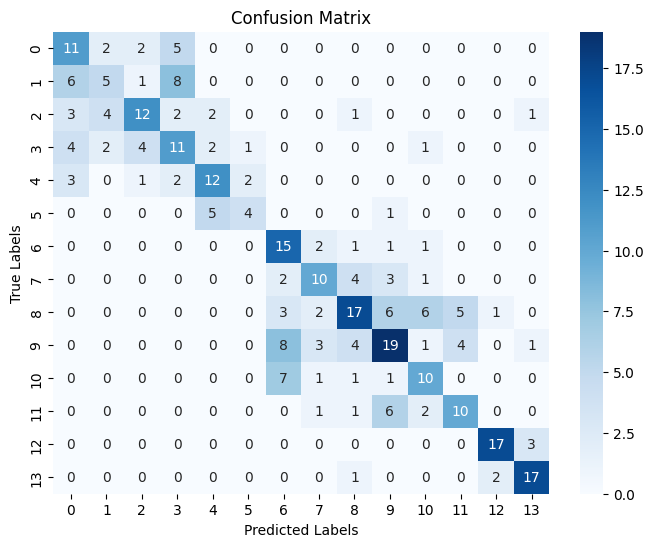

In [6]:
# Assuming 'y_test' and 'y_test_pred' are defined from the previous code
cm = confusion_matrix(y_test, y_test_pred)

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()


In [7]:
class_names = os.listdir(train_dir)
for index, class_name in enumerate(class_names):
  print(f"Class index: {index}, Class name: {class_name}")


Class index: 0, Class name: w3.ca
Class index: 1, Class name: w7.d
Class index: 2, Class name: w6.ero
Class index: 3, Class name: w4.ev
Class index: 4, Class name: w5.ec
Class index: 5, Class name: w8.s
Class index: 6, Class name: n4.ev
Class index: 7, Class name: n1.n
Class index: 8, Class name: w1.n
Class index: 9, Class name: n3.ca
Class index: 10, Class name: n2.dys
Class index: 11, Class name: w2.dys
Class index: 12, Class name: n5.ec
Class index: 13, Class name: n6.ero


In [14]:
class_names = os.listdir(train_dir)
for index, class_name in enumerate(class_names):
  print(f"{class_name}")

w3.ca
w7.d
w6.ero
w4.ev
w5.ec
w8.s
n4.ev
n1.n
w1.n
n3.ca
n2.dys
w2.dys
n5.ec
n6.ero


In [8]:
# Assuming 'train_dir' is the directory containing subdirectories for each class
class_names = os.listdir(train_dir)

for index, class_name in enumerate(class_names):
  print(f"Index: {index}, Class Name: {class_name}")


Index: 0, Class Name: w3.ca
Index: 1, Class Name: w7.d
Index: 2, Class Name: w6.ero
Index: 3, Class Name: w4.ev
Index: 4, Class Name: w5.ec
Index: 5, Class Name: w8.s
Index: 6, Class Name: n4.ev
Index: 7, Class Name: n1.n
Index: 8, Class Name: w1.n
Index: 9, Class Name: n3.ca
Index: 10, Class Name: n2.dys
Index: 11, Class Name: w2.dys
Index: 12, Class Name: n5.ec
Index: 13, Class Name: n6.ero


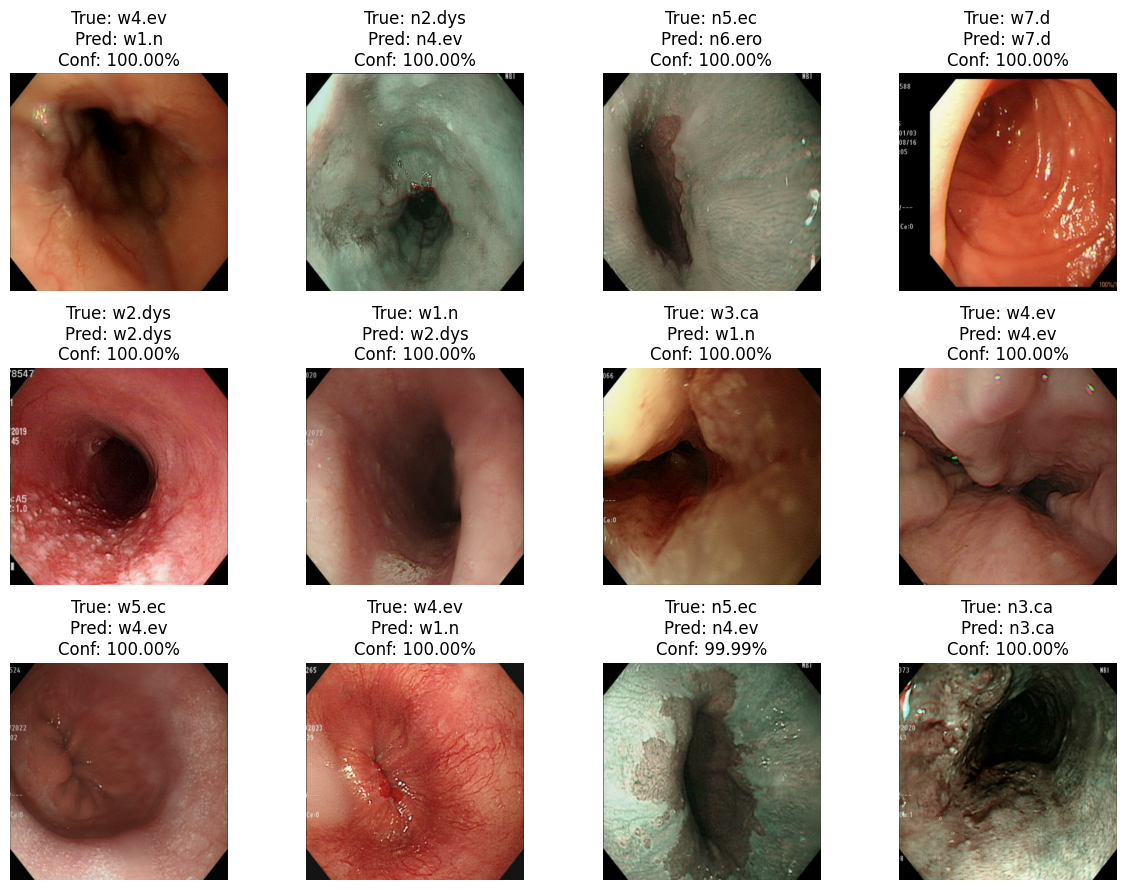

In [22]:
import matplotlib.pyplot as plt
import numpy as np

# Assuming you have already loaded your test dataset and logistic model

# Make predictions and get prediction probabilities for the test dataset
y_test_pred = logistic_model.predict(X_test)  # Predicted labels
y_test_prob = logistic_model.predict_proba(X_test)  # Probabilities of each class

# Function to display images with predictions and confidence
def display_predictions(images, true_labels, predicted_labels, probabilities, class_names, num_images=12):
    plt.figure(figsize=(12, 9))  # Set the figure size
    for i in range(num_images):
        plt.subplot(3, 4, i + 1)  # 3x4 grid for displaying 12 images
        img = images[i].reshape(640, 640, 3)  # Reshape flat image back to 3D (adjust according to image size)
        plt.imshow(img)
        true_label = class_names[true_labels[i]]
        predicted_label = class_names[predicted_labels[i]]
        confidence = np.max(probabilities[i]) * 100  # Highest probability as confidence score
        plt.title(f"True: {true_label}\nPred: {predicted_label}\nConf: {confidence:.2f}%")
        plt.axis('off')  # Turn off axis

    plt.tight_layout()
    plt.show()

# Assuming you have your class names available
class_names = ['n1.n', 'n2.dys', 'n3.ca', 'n4.ev', 'n5.ec', 'n6.ero', 'w1.n', 'w2.dys','w3.ca', 'w4.ev','w5.ec', 'w6.ero', 'w7.d', 'w8.s']  # Replace with your actual class names

# Display 12 predictions
display_predictions(test_flat_data, y_test, y_test_pred, y_test_prob, class_names, num_images=12) # Changed test_images to test_flat_data

In [20]:
import joblib
# Save the trained Logistic Regression model to your working directory
joblib.dump(logistic_model, '/content/drive/MyDrive/Arvind/logistic_regression_model.pkl')


['/content/drive/MyDrive/Arvind/logistic_regression_model.pkl']